In [5]:
import seaborn as sns

# সবচেয়ে বড় ডেটাসেট লোড করতে:
df = sns.load_dataset('diamonds')
print(df.shape)  # আউটপুট: (53940, 10)
df.sample(5)

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
36838,0.37,Premium,G,VS1,61.4,58.0,957,4.61,4.58,2.82
26042,2.07,Very Good,I,SI2,63.1,57.0,15245,8.20,8.10,5.14
39064,0.40,Ideal,G,VVS1,61.2,56.0,1059,4.74,4.80,2.92
49499,0.55,Ideal,F,VS1,60.5,57.0,2119,5.30,5.34,3.22
20755,1.53,Premium,E,SI2,58.9,59.0,8996,7.63,7.55,4.47


In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = sns.load_dataset('diamonds')

print('Shape:', df.shape)
print('\nFirst 5 rows:')
print(df.head())

print('\nInfo:')
print(df.info())

Shape: (53940, 10)

First 5 rows:
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  floa

In [10]:
print(df.describe())

print('\nDuplicate rows:', df.duplicated().sum())

print("ক্যাটাগরিক্যাল কলামগুলোর ভ্যালু কাউন্ট")
for col in ['cut', 'color', 'clarity']:
  print(f'\n--- {col} ---')
  print(df[col].value_counts())

              carat         depth         table         price             x  \
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000   
mean       0.797940     61.749405     57.457184   3932.799722      5.731157   
std        0.474011      1.432621      2.234491   3989.439738      1.121761   
min        0.200000     43.000000     43.000000    326.000000      0.000000   
25%        0.400000     61.000000     56.000000    950.000000      4.710000   
50%        0.700000     61.800000     57.000000   2401.000000      5.700000   
75%        1.040000     62.500000     59.000000   5324.250000      6.540000   
max        5.010000     79.000000     95.000000  18823.000000     10.740000   

                  y             z  
count  53940.000000  53940.000000  
mean       5.734526      3.538734  
std        1.142135      0.705699  
min        0.000000      0.000000  
25%        4.720000      2.910000  
50%        5.710000      3.530000  
75%        6.540000      4.040000  


In [13]:
# শূন্য মাত্রার (dimension = 0) রো দেখা
invalid_dims = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]
print('Invalid dimension rows:', len(invalid_dims))

# ক্লিন কপি তৈরি (প্রয়োজনে)
df_clean = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)].copy()

# নতুন ফিচার: ভলিউম (approximate) ও প্রতি ক্যারেটে দাম
df_clean['volume'] = df_clean['x'] * df_clean['y'] * df_clean['z']
df_clean['price_per_carat'] = df_clean['price'] / df_clean['carat']

Invalid dimension rows: 20


In [16]:
df.head()
print('Invalid dimension rows:', (invalid_dims))

Invalid dimension rows:        carat        cut color clarity  depth  table  price     x     y    z
2207    1.00    Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01    Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10    Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01    Premium     F     SI2   59.2   58.0   3837  6.50  6.47  0.0
10167   1.50       Good     G      I1   64.0   61.0   4731  7.15  7.04  0.0
11182   1.07      Ideal     F     SI2   61.6   56.0   4954  0.00  6.62  0.0
11963   1.00  Very Good     H     VS2   63.3   53.0   5139  0.00  0.00  0.0
13601   1.15      Ideal     G     VS2   59.2   56.0   5564  6.88  6.83  0.0
15951   1.14       Fair     G     VS1   57.5   67.0   6381  0.00  0.00  0.0
24394   2.18    Premium     H     SI2   59.4   61.0  12631  8.49  8.45  0.0
24520   1.56      Ideal     G     VS2   62.2   54.0  12800  0.00  0.00  0.0
26123   2.25    Premium     I     SI1   61.3   58.0  15397  8.52

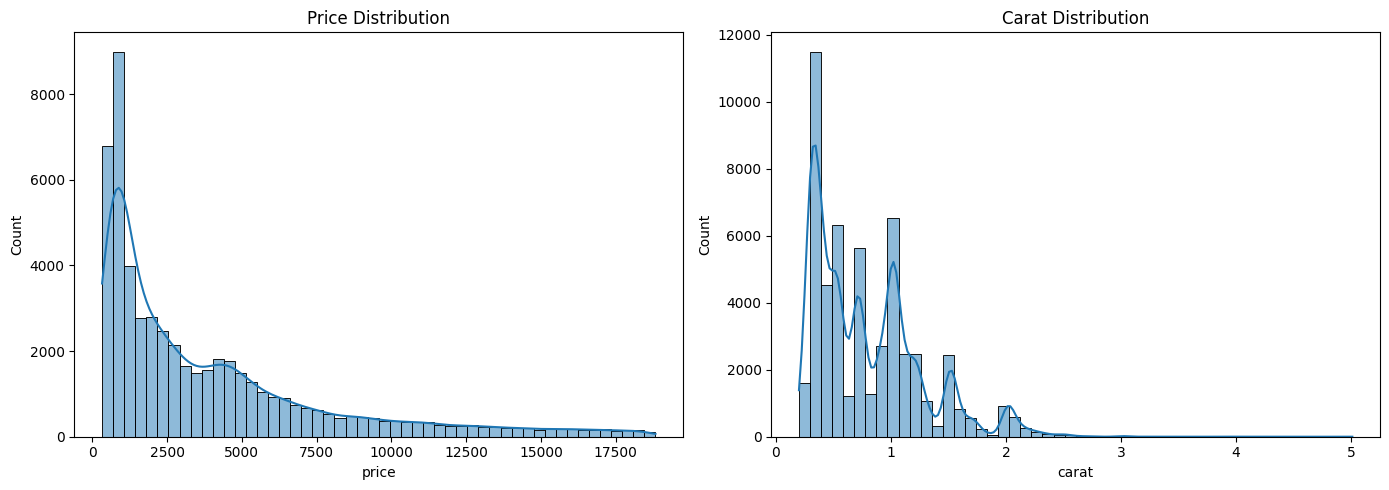

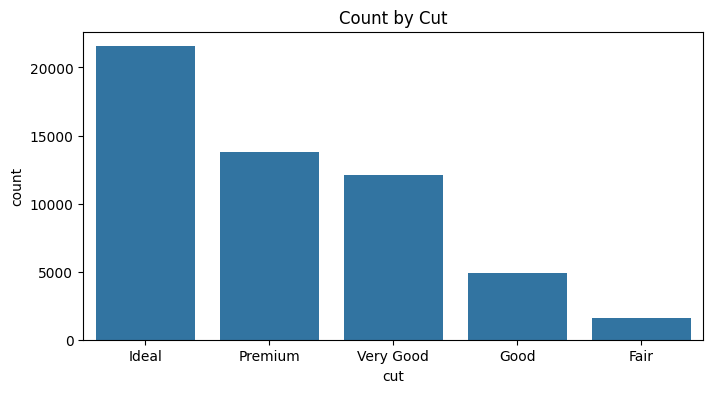

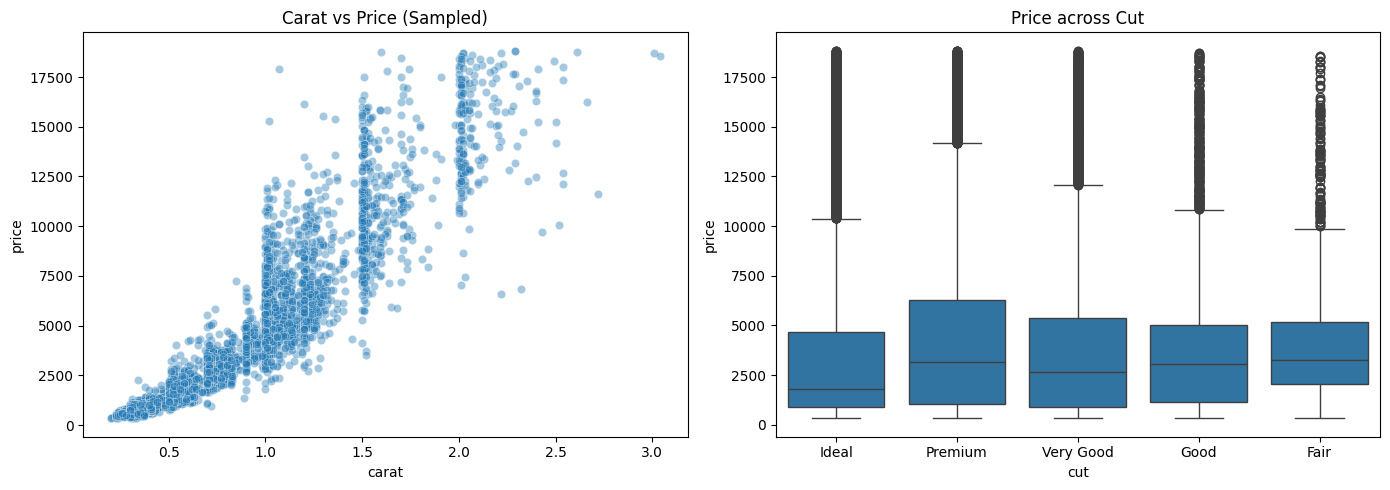

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price distribution
sns.histplot(df_clean['price'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')

# Carat distribution
sns.histplot(df_clean['carat'], bins=50, kde=True, ax=axes[1])
axes[1].set_title('Carat Distribution')

plt.tight_layout()
plt.show()

# Cut distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='cut', order=df_clean['cut'].value_counts().index)
plt.title('Count by Cut')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Carat vs Price
sns.scatterplot(data=df_clean.sample(5000, random_state=42), x='carat', y='price', alpha=0.4, ax=axes[0])
axes[0].set_title('Carat vs Price (Sampled)')

# Cut vs Price
sns.boxplot(data=df_clean, x='cut', y='price', ax=axes[1])
axes[1].set_title('Price across Cut')

plt.tight_layout()
plt.show()

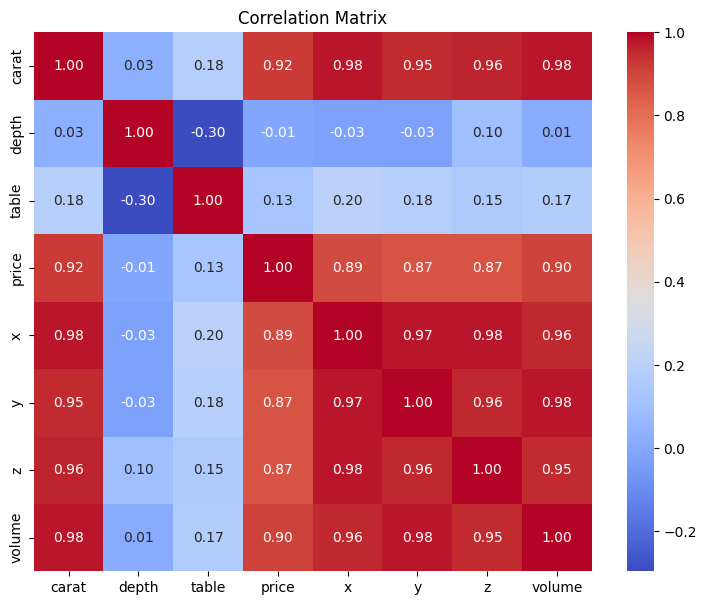

In [20]:
numeric_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z', 'volume']
corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()



/tmp/ipykernel_2460/1679719197.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_price = df_clean.pivot_table(values='price', index='cut', columns='color', aggfunc='median')


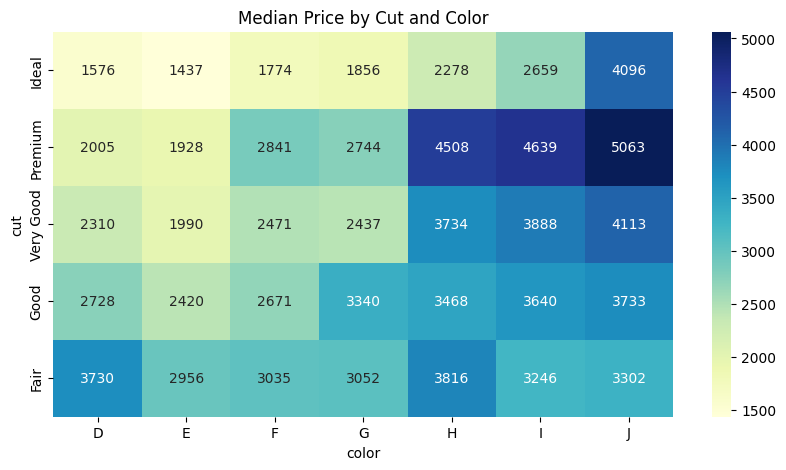

In [21]:
# Cut ও Color অনুযায়ী গড় দাম
pivot_price = df_clean.pivot_table(values='price', index='cut', columns='color', aggfunc='median')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot_price, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Median Price by Cut and Color')
plt.show()

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns


def generate_diamonds_insights():
  # ১. ডেটা লোড ও প্রাথমিক ক্লিনিং
  df = sns.load_dataset('diamonds')
  zero_dims = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]

  clean_df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)].copy()
  clean_df['price_per_carat'] = clean_df['price'] / clean_df['carat']
  clean_df['volume'] = clean_df['x'] * clean_df['y'] * clean_df['z']

  print('================ DIAMONDS DATASET INSIGHTS ================\n')

  # ২. ডেটার আকার ও কোয়ালিটি ইনসাইট
  print('1. Data Overview & Quality:')
  print(
      f'   - Total rows: {len(df):,}, Columns: {df.shape[1]}, Missing values:'
      f' {df.isnull().sum().sum()}'
  )
  print(f'   - Duplicate rows: {df.duplicated().sum():,}')
  print(
      f'   - Invalid dimension rows (x, y, or z == 0): {len(zero_dims)}'
      ' (removed for clean analysis)'
  )

  # ৩. দাম ও ক্যারেট ইনসাইট
  min_price = clean_df['price'].min()
  max_price = clean_df['price'].max()
  median_price = clean_df['price'].median()
  mean_price = clean_df['price'].mean()
  skew_price = clean_df['price'].skew()

  print('\n2. Price & Carat Insights:')
  print(
      f'   - Price range: ${min_price:,} to ${max_price:,} | Median:'
      f' ${median_price:,.0f} | Mean: ${mean_price:,.0f}'
  )
  print(
      f'   - Price skewness: {skew_price:.2f} (strongly right-skewed due to'
      ' high-end diamonds)'
  )
  print(
      f'   - Carat range: {clean_df["carat"].min()} to'
      f' {clean_df["carat"].max()} | Median carat:'
      f' {clean_df["carat"].median()}'
  )

  # ৪. কোরিলেশন ইনসাইট (Price-এর সাথে সবচেয়ে বেশি সম্পর্কিত ফিচার)
  corr_with_price = (
      clean_df[['carat', 'depth', 'table', 'x', 'y', 'z', 'volume', 'price']]
      .corr()['price']
      .drop('price')
      .sort_values(ascending=False)
  )

  print('\n3. Top Drivers Correlated with Price:')
  for feat, val in corr_with_price.head(3).items():
    print(f'   - {feat}: correlation = {val:.2f}')

  # ৫. ক্যাটাগরিভিত্তিক (Cut, Color, Clarity) ইনসাইট
  top_cut = clean_df['cut'].value_counts().index[0]
  top_cut_pct = clean_df['cut'].value_counts(normalize=True).iloc[0] * 100

  highest_median_cut = (
      clean_df.groupby('cut', observed=False)['price'].median().idxmax()
  )
  highest_median_cut_val = (
      clean_df.groupby('cut', observed=False)['price'].median().max()
  )

  best_ppc_clarity = (
      clean_df.groupby('clarity', observed=False)['price_per_carat']
      .median()
      .idxmax()
  )
  best_ppc_color = (
      clean_df.groupby('color', observed=False)['price_per_carat']
      .median()
      .idxmax()
  )

  print('\n4. Category Insights:')
  print(f'   - Most common cut: {top_cut} ({top_cut_pct:.1f}% of dataset)')
  print(
      f'   - Highest median price by cut: {highest_median_cut}'
      f' (${highest_median_cut_val:,.0f})'
  )
  print(f'   - Highest median price-per-carat clarity: {best_ppc_clarity}')
  print(f'   - Highest median price-per-carat color: {best_ppc_color}')


if __name__ == '__main__':
  generate_diamonds_insights()

================ DIAMONDS DATASET INSIGHTS ================

1. Data Overview & Quality:
   - Total rows: 53,940, Columns: 10, Missing values: 0
   - Duplicate rows: 146
   - Invalid dimension rows (x, y, or z == 0): 20 (removed for clean analysis)

2. Price & Carat Insights:
   - Price range: $326 to $18,823 | Median: $2,401 | Mean: $3,931
   - Price skewness: 1.62 (strongly right-skewed due to high-end diamonds)
   - Carat range: 0.2 to 5.01 | Median carat: 0.7

3. Top Drivers Correlated with Price:
   - carat: correlation = 0.92
   - volume: correlation = 0.90
   - x: correlation = 0.89

4. Category Insights:
   - Most common cut: Ideal (40.0% of dataset)
   - Highest median price by cut: Fair ($3,282)
   - Highest median price-per-carat clarity: SI2
   - Highest median price-per-carat color: H
